# Requirement Dataset Cleaning (Local Environment)
## Research: Requirement Prioritization

**Pipeline Flow:**
1. Basic Normalization (Lowercase → Remove URLs/e.g./i.e. → Merge Compounds → Separate Number Handling for TF-IDF & Word2Vec → Remove Punctuation → Whitespace)
2. Tokenization (Word2Vec tokens finalized & rejoined)
3. Stop Word Removal (NLTK + Domain Boilerplate, with Priority & CRUD Action Whitelist)
4. POS-Guided Lemmatization (POS Tagging on raw tokens before stopword removal; Protected Tech Terms)
5. Cleansing: Deduplication & Minimum Length Filtering
6. Export to Excel & CSV (12 standard columns)

---
## 0. Install & Download Dependencies

In [1]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "openpyxl", "nltk"])

import nltk
nltk.download("punkt",                          quiet=True)
nltk.download("punkt_tab",                      quiet=True)
nltk.download("stopwords",                      quiet=True)
nltk.download("wordnet",                        quiet=True)
nltk.download("omw-1.4",                        quiet=True)
nltk.download("averaged_perceptron_tagger",     quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

print("Dependencies ready.")

Dependencies ready.


---
## 1. Import Libraries

In [2]:
import re
import pandas as pd
import numpy as np
from openpyxl import load_workbook

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer

print("All libraries imported successfully.")

All libraries imported successfully.


---
## 2. Load Dataset

Reads directly from the `Dataset` sheet of the Excel file located in the local directory (e.g., `dataset/` or `datasets/`).

In [3]:
import os

# ── Local Dataset Configuration ─────────────────────────────────────────────
# Path dataset lokal di root folder dataset/ (atau datasets/)
CANDIDATE_PATHS = [
    os.path.join("dataset", "Dataset.xlsx"),
    os.path.join("dataset", "Dataset_recalculated_priority.xlsx"),
    os.path.join("datasets", "Dataset_recalculated_priority.xlsx"),
    os.path.join("datasets", "Dataset.xlsx"),
    "Dataset.xlsx"
]

FILE_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), os.path.join("dataset", "Dataset.xlsx"))
print(f"Loading dataset from: '{FILE_PATH}'")

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"File dataset tidak ditemukan di '{FILE_PATH}'. "
        f"Pastikan file dataset ditaruh di folder 'dataset/' (contoh: 'dataset/Dataset.xlsx')."
    )

SHEET_NAME = "Dataset"

wb = load_workbook(FILE_PATH, read_only=True, data_only=True)
ws = wb[SHEET_NAME]

rows = list(ws.iter_rows(values_only=True))
headers = rows[0]
data    = rows[1:]

df = pd.DataFrame(data, columns=headers)

df = df.dropna(how="all").reset_index(drop=True)

# Ensure numeric columns are properly typed
for col in ["value", "effort", "risk", "stakeholder_priority"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Recompute priority_score and rank from source values
# Formula: (value * 0.4) + (effort * 0.3) - (risk * 0.2) - (stakeholder_priority * 0.1)
df["priority_score"] = (
    df["value"] * 0.4
    + df["effort"] * 0.3
    - df["risk"] * 0.2
    - df["stakeholder_priority"] * 0.1
).round(2)

# Rank within each project (descending score = rank 1 is best)
df["rank"] = (
    df.groupby("project_id")["priority_score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

print(f"Dataset loaded  : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Columns         : {list(df.columns)}")
df.head(3)

Loading dataset from: 'dataset\Dataset.xlsx'
Dataset loaded  : 955 rows x 11 columns
Columns         : ['id', 'project_id', 'requirement_text', 'type', 'prespective', 'value', 'effort', 'risk', 'stakeholder_priority', 'priority_score', 'rank']


,id,project_id,requirement_text,type,prespective,value,effort,risk,stakeholder_priority,priority_score,rank
0,REQ-01,P1,The system provides a feature for the Head Adm...,FR,System,3,2,1,3,1.3,18
1,REQ-02,P1,The system provides a feature for the Head Adm...,FR,System,3,2,1,3,1.3,18
2,REQ-03,P1,The system provides a feature for the Head Adm...,FR,System,3,2,1,3,1.3,18


---
## Vocab Cloud

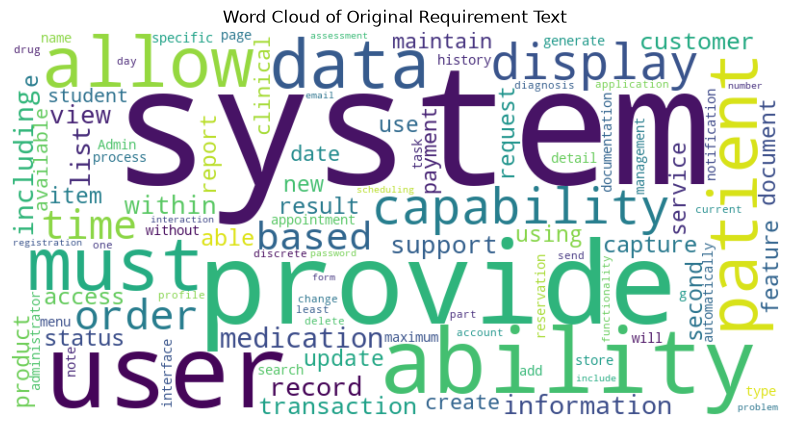

In [4]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Combine all original requirement texts into a single string
all_words = ' '.join(df['requirement_text'].astype(str))

# Generate word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100,
    collocations=False  # Avoid displaying duplicates of words
).generate(all_words)

# Display the generated image:
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Original Requirement Text')
plt.show()

---
## 3. Initial Validation

In [5]:
REQUIRED_COLUMNS = [
    "id", "project_id", "requirement_text", "type",
    "value", "effort", "risk", "stakeholder_priority", "priority_score", "rank"
]

missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

print("All required columns are present.")
print("\nNull counts per column:")
print(df[REQUIRED_COLUMNS].isnull().sum())

# Ensure requirement_text is string
df["requirement_text"] = df["requirement_text"].astype(str)

All required columns are present.

Null counts per column:
id                      0
project_id              0
requirement_text        0
type                    0
value                   0
effort                  0
risk                    0
stakeholder_priority    0
priority_score          0
rank                    0
dtype: int64


---
## 4. Basic Normalization

Steps:
1. **Lowercase** — convert all text to lowercase
2. **Remove URLs** — strip http/https/www links
3. **Remove Abbreviations** — remove 'e.g.' and 'i.e.' to prevent single-letter fragments ('e', 'g', 'i')
4. **Merge Hyphenated Compounds** — merge common SE compound terms (e.g., wi-fi → wifi, multi-tenant → multitenant)
5. **Handle Standalone Numbers**:
   - For Word2Vec (`keep_numbers_as_token=True`): replace standalone numbers with `' num '` token
   - For TF-IDF (`keep_numbers_as_token=False`): remove standalone numbers while keeping alphanumeric codes (e.g., 2fa, sha256)
6. **Remove Punctuation** — keep only alphanumeric and whitespace
7. **Remove Whitespace** — collapse multiple spaces and trim edges

In [6]:
def normalize_text(text: str, keep_numbers_as_token: bool = False) -> str:
    """
    Basic normalization pipeline:
    1. Lowercase
    2. Remove URLs (http / https / www)
    3. Remove abbreviations 'e.g.' and 'i.e.'
    4. Merge common SE hyphenated compounds (wifi, pre-, non-, etc.)
    5. Handle standalone numbers (replace with ' num ' for Word2Vec, remove for TF-IDF)
    6. Remove non-alphanumeric punctuation
    7. Collapse whitespace
    """
    # 1. Lowercase
    text = text.lower()

    # 2. Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # 3. Remove 'e.g.' and 'i.e.' to prevent single-letter tokens ('e', 'g', 'i')
    text = re.sub(r"\be\.g\.|\bi\.e\.", " ", text)

    # 4. Merge common hyphenated compound words in software engineering
    text = re.sub(r"\b(wi)-?(fi)\b", "wifi", text)
    text = re.sub(r"\b(e|co|re|pre|non|sub|multi|auto|self|two|three)-([a-z0-9]+)\b", r"\1\2", text)

    # 5. Handle standalone numbers
    if keep_numbers_as_token:
        # For Word2Vec: replace standalone numbers with ' num ' token
        text = re.sub(r"(?<![a-z])\d+(\.\d+)?(?![a-z])", " num ", text)
    else:
        # For TF-IDF: remove standalone numbers while keeping alphanumeric combinations (e.g. 2fa, sha256)
        text = re.sub(r"(?<![a-z])\d+(\.\d+)?(?![a-z])", " ", text)

    # 6. Remove non-alphanumeric punctuation
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # 7. Collapse whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [7]:
df["normalized_tfidf"] = df["requirement_text"].apply(lambda x: normalize_text(x, keep_numbers_as_token=False))
df["normalized_w2v"] = df["requirement_text"].apply(lambda x: normalize_text(x, keep_numbers_as_token=True))

print("Basic normalization complete. Sample results:")
pd.set_option("display.max_colwidth", 120)
print(df[["requirement_text", "normalized_tfidf", "normalized_w2v"]].head(5).to_string(index=False))

Basic normalization complete. Sample results:
                                                                                                                                requirement_text                                                                                                                             normalized_tfidf                                                                                                                               normalized_w2v
                                    The system provides a feature for the Head Admin and Finance to add, edit, and delete spare part categories.                                    the system provides a feature for the head admin and finance to add edit and delete spare part categories                                    the system provides a feature for the head admin and finance to add edit and delete spare part categories
                                          The system provides a feature for the Head Admin and Finan

---
## 5. Tokenization

Split normalized text into individual word tokens using NLTK `word_tokenize`.
- **TF-IDF branch**: Tokens will undergo POS tagging, domain-stopword removal, and lemmatization.
- **Word2Vec branch**: Full token sequence is finalized and rejoined (`cleaned_text_w2v`) without stopword removal or lemmatization to protect sliding-window context and anchor words.

In [8]:
def tokenize(text: str) -> list:
    """Tokenize text into a list of string tokens using NLTK word_tokenize."""
    return word_tokenize(text)

In [9]:
df["tokens_tfidf_raw"] = df["normalized_tfidf"].apply(tokenize)
df["tokens_w2v"] = df["normalized_w2v"].apply(lambda x: [t for t in tokenize(x) if t.isalnum()])

# For Word2Vec, rejoin immediately into cleaned_text_w2v (preserving sentence structure)
df["cleaned_text_w2v"] = df["tokens_w2v"].apply(lambda t: " ".join(t))

print("Tokenization complete. Sample results:")
for i, row in df[["tokens_tfidf_raw", "tokens_w2v", "cleaned_text_w2v"]].head(3).iterrows():
    print(f"  [{i}] TF-IDF raw tokens : {row['tokens_tfidf_raw'][:8]} ...")
    print(f"       W2V cleaned text  : {row['cleaned_text_w2v'][:80]} ...")
    print()

Tokenization complete. Sample results:
  [0] TF-IDF raw tokens : ['the', 'system', 'provides', 'a', 'feature', 'for', 'the', 'head'] ...
       W2V cleaned text  : the system provides a feature for the head admin and finance to add edit and del ...

  [1] TF-IDF raw tokens : ['the', 'system', 'provides', 'a', 'feature', 'for', 'the', 'head'] ...
       W2V cleaned text  : the system provides a feature for the head admin and finance to add edit and del ...

  [2] TF-IDF raw tokens : ['the', 'system', 'provides', 'a', 'feature', 'for', 'the', 'head'] ...
       W2V cleaned text  : the system provides a feature for the head admin and finance to add edit and del ...



---
## 6. Stop Word Removal (TF-IDF Path)

Using NLTK English stopwords plus curated domain boilerplate stopwords, with a strict whitelist protecting requirement priority modal verbs and CRUD action verbs.

In [10]:
BASE_STOPWORDS = set(stopwords.words("english"))

# Whitelist: Critical requirement priority modals and CRUD action verbs that must NEVER be removed
PRIORITY_AND_CRUD_WHITELIST = {
    "must", "shall", "should", "may", "might", "need", "needs", "required", "require",
    "add", "view", "list", "set", "get", "show", "create", "edit", "delete", "update",
    "not", "no", "nor", "non", "only", "all", "every", "each"
}

# Domain boilerplate stopwords: generic requirement terms with no discriminative prioritization value
DOMAIN_STOPWORDS = {
    "system", "systems", "feature", "features", "provide", "provides", "provided", "providing",
    "allow", "allows", "allowed", "allowing", "able", "ability", "capability", "capabilities",
    "function", "functions", "functionality", "use", "used", "using", "user", "users",
    "based", "related", "given", "within", "also", "via", "well", "could", "would",
    "make", "makes", "application", "applications", "module", "modules",
    "interface", "interfaces", "eg", "etc", "ie"
}

# Combine and subtract the whitelist
ALL_STOPWORDS = (BASE_STOPWORDS.union(DOMAIN_STOPWORDS)) - PRIORITY_AND_CRUD_WHITELIST

print(f"Total stopwords active : {len(ALL_STOPWORDS)}")
print(f"  NLTK base stopwords  : {len(BASE_STOPWORDS)}")
print(f"  Domain boilerplate   : {len(DOMAIN_STOPWORDS)}")
print(f"  Whitelisted terms    : {len(PRIORITY_AND_CRUD_WHITELIST)}")

Total stopwords active : 235
  NLTK base stopwords  : 198
  Domain boilerplate   : 44
  Whitelisted terms    : 27


In [11]:
def remove_stopwords(tokens: list) -> list:
    """Filter out stopwords, keeping only alphanumeric non-stopword tokens."""
    return [
        token for token in tokens
        if token.isalnum() and token not in ALL_STOPWORDS
    ]

# Note: In Section 7, stopword removal is integrated directly with POS-guided lemmatization
# on `tokens_tfidf_raw` so that nltk.pos_tag has full sentence syntactic context.
sample_preview = df["tokens_tfidf_raw"].head(3).apply(remove_stopwords)
print("Stop word configuration verified. Sample preview:")
for i, orig in enumerate(df["tokens_tfidf_raw"].head(3)):
    filtered = sample_preview.iloc[i]
    print(f"  [{i}] before : {orig[:8]}")
    print(f"       after  : {filtered[:8]}")
    print()

Stop word configuration verified. Sample preview:
  [0] before : ['the', 'system', 'provides', 'a', 'feature', 'for', 'the', 'head']
       after  : ['head', 'admin', 'finance', 'add', 'edit', 'delete', 'spare', 'part']

  [1] before : ['the', 'system', 'provides', 'a', 'feature', 'for', 'the', 'head']
       after  : ['head', 'admin', 'finance', 'add', 'edit', 'delete', 'car', 'master']

  [2] before : ['the', 'system', 'provides', 'a', 'feature', 'for', 'the', 'head']
       after  : ['head', 'admin', 'finance', 'add', 'edit', 'delete', 'engine', 'master']



---
## 7. Stemming — WordNet Lemmatization (POS-Guided)

Reduce tokens to their base/lemma form using `WordNetLemmatizer` with POS Tagging (`nltk.pos_tag`) applied to raw tokens before stopword removal.
- Avoids the flawed length heuristic `len(lemma_v) <= len(lemma_n)` (which corrupted "rating" → "rat", "coded" → "cod", "routing" → "rout").
- Maps Treebank POS tags to WordNet POS categories (`ADJ`, `VERB`, `NOUN`, `ADV`).
- Protects common software/networking acronyms ending in 's' (e.g., `tls`, `dos`, `sms`, `aws`, `ios`).

In [12]:
lemmatizer = WordNetLemmatizer()

PROTECTED_TECH_TERMS = {
    "pos", "tls", "dos", "bps", "mbps", "fps", "gps", "sms", "cms", "dms", "aws", "ios"
}

def get_wordnet_pos(treebank_tag: str):
    """Map Treebank POS tag to WordNet POS constant."""
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    elif treebank_tag.startswith("V"):
        return wordnet.VERB
    elif treebank_tag.startswith("N"):
        return wordnet.NOUN
    elif treebank_tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN

def lemmatize_tokens(tokens: list) -> list:
    """
    POS-guided lemmatization on raw TF-IDF tokens:
    1. Perform POS tagging on tokens using nltk.pos_tag (preserving sentence context).
    2. Skip tokens that are non-alphanumeric, < 2 chars, or in ALL_STOPWORDS.
    3. If token in PROTECTED_TECH_TERMS, retain it unchanged.
    4. Otherwise, lemmatize using the WordNet POS mapping.
    5. Secondary check: ensure lemma not in ALL_STOPWORDS and len(lemma) >= 2.
    """
    tagged = nltk.pos_tag(tokens)
    lemmatized = []

    for token, tag in tagged:
        if not token.isalnum() or len(token) < 2 or token in ALL_STOPWORDS:
            continue

        if token in PROTECTED_TECH_TERMS:
            lemma = token
        else:
            wn_pos = get_wordnet_pos(tag)
            lemma = lemmatizer.lemmatize(token, pos=wn_pos)

        if lemma not in ALL_STOPWORDS and len(lemma) >= 2:
            lemmatized.append(lemma)

    return lemmatized

In [13]:
df["tokens_lemma"] = df["tokens_tfidf_raw"].apply(lemmatize_tokens)

# Rejoin tokens into cleaned TF-IDF text
df["cleaned_text_tfidf"] = df["tokens_lemma"].apply(lambda t: " ".join(t))

print("POS-guided lemmatization complete. Comparison sample:")
comparison = df[["requirement_text", "cleaned_text_tfidf", "cleaned_text_w2v"]].head(5)
print(comparison.to_string(index=False))

POS-guided lemmatization complete. Comparison sample:
                                                                                                                                requirement_text                                                                      cleaned_text_tfidf                                                                                                                             cleaned_text_w2v
                                    The system provides a feature for the Head Admin and Finance to add, edit, and delete spare part categories.                                  head admin finance add edit delete spare part category                                    the system provides a feature for the head admin and finance to add edit and delete spare part categories
                                          The system provides a feature for the Head Admin and Finance to add, edit, and delete car master data.                                      head admin finan

---
## 8. Cleansing: Duplication & Normalization Techniques

- Detect and report exact duplicates on raw text
- Detect and report semantic duplicates on `cleaned_text_tfidf`
- Remove duplicates (keep first occurrence) based on `cleaned_text_tfidf`
- Remove rows where `cleaned_text_tfidf` or `cleaned_text_w2v` is too short (< 2 characters)

In [14]:
# 8a. Check exact duplicates on raw requirement_text
n_total_before = len(df)
n_dup_raw = df.duplicated(subset=["requirement_text"], keep=False).sum()

print(f"Total rows before dedup          : {n_total_before}")
print(f"Duplicate rows (exact raw text)  : {n_dup_raw}")

if n_dup_raw > 0:
    print("\nSample exact duplicates (requirement_text):")
    dup_sample = (
        df[df.duplicated(subset=["requirement_text"], keep=False)]
        [["id", "requirement_text"]]
        .head(6)
    )
    print(dup_sample.to_string(index=False))

Total rows before dedup          : 955
Duplicate rows (exact raw text)  : 6

Sample exact duplicates (requirement_text):
     id                                                                                  requirement_text
REQ-128 These instructions may reside within the system or be provided through links to external sources.
REQ-130 These instructions may reside within the system or be provided through links to external sources.
REQ-663                 The system must display a summary of total debts and receivables for each member.
REQ-664                 The system must display a summary of total debts and receivables for each member.
REQ-792               The system shall display a non-clinical disclaimer on every assessment result page.
REQ-811               The system shall display a non-clinical disclaimer on every assessment result page.


In [15]:
# 8b. Check semantic duplicates on cleaned_text_tfidf
n_dup_clean = df.duplicated(subset=["cleaned_text_tfidf"], keep=False).sum()
print(f"Duplicate rows (cleaned text)    : {n_dup_clean}")

if n_dup_clean > 0:
    print("\nSample semantic duplicates (cleaned_text_tfidf):")
    dup_proc_sample = (
        df[df.duplicated(subset=["cleaned_text_tfidf"], keep=False)]
        [["id", "requirement_text", "cleaned_text_tfidf"]]
        .head(6)
    )
    print(dup_proc_sample.to_string(index=False))

Duplicate rows (cleaned text)    : 6

Sample semantic duplicates (cleaned_text_tfidf):
     id                                                                                  requirement_text                                                cleaned_text_tfidf
REQ-128 These instructions may reside within the system or be provided through links to external sources.                       instruction may reside link external source
REQ-130 These instructions may reside within the system or be provided through links to external sources.                       instruction may reside link external source
REQ-663                 The system must display a summary of total debts and receivables for each member.           must display summary total debt receivables each member
REQ-664                 The system must display a summary of total debts and receivables for each member.           must display summary total debt receivables each member
REQ-792               The system shall display a non-

In [16]:
# 8c. Remove duplicates based on cleaned text (stricter — catches semantic dupes)
df_clean = df.drop_duplicates(subset=["cleaned_text_tfidf"], keep="first").reset_index(drop=True)
n_removed_dup = n_total_before - len(df_clean)
print(f"Rows removed (duplicates)        : {n_removed_dup}")
print(f"Rows remaining after dedup       : {len(df_clean)}")

Rows removed (duplicates)        : 3
Rows remaining after dedup       : 952


In [17]:
# 8d. Remove rows with empty or too-short cleaned text (< 2 characters in tfidf or w2v)
MIN_LENGTH = 2
mask_too_short = (
    (df_clean["cleaned_text_tfidf"].str.strip().str.len() < MIN_LENGTH) |
    (df_clean["cleaned_text_w2v"].str.strip().str.len() < MIN_LENGTH)
)
n_empty = mask_too_short.sum()

if n_empty > 0:
    print(f"Rows with cleaned text too short : {n_empty}")
    df_clean = df_clean[~mask_too_short].reset_index(drop=True)
else:
    print("No rows with empty cleaned text.")

print(f"\nFinal clean dataset              : {df_clean.shape[0]} rows")

No rows with empty cleaned text.

Final clean dataset              : 952 rows


---
## 9. Prepare Final Output

Select only the 12 required output columns in the specified order.

In [18]:
OUTPUT_COLUMNS = [
    "id",
    "project_id",
    "requirement_text",
    "cleaned_text_tfidf",
    "cleaned_text_w2v",
    "type",
    "value",
    "effort",
    "risk",
    "stakeholder_priority",
    "priority_score",
    "rank"
]

df_out = df_clean[OUTPUT_COLUMNS].copy()

print(f"Output shape : {df_out.shape}")
print(f"Columns ({len(df_out.columns)}) : {list(df_out.columns)}")
df_out.head(5)

Output shape : (952, 12)
Columns (12) : ['id', 'project_id', 'requirement_text', 'cleaned_text_tfidf', 'cleaned_text_w2v', 'type', 'value', 'effort', 'risk', 'stakeholder_priority', 'priority_score', 'rank']


,id,project_id,requirement_text,cleaned_text_tfidf,cleaned_text_w2v,type,value,effort,risk,stakeholder_priority,priority_score,rank
0,REQ-01,P1,"The system provides a feature for the Head Admin and Finance to add, edit, and delete spare part categories.",head admin finance add edit delete spare part category,the system provides a feature for the head admin and finance to add edit and delete spare part categories,FR,3,2,1,3,1.3,18
1,REQ-02,P1,"The system provides a feature for the Head Admin and Finance to add, edit, and delete car master data.",head admin finance add edit delete car master data,the system provides a feature for the head admin and finance to add edit and delete car master data,FR,3,2,1,3,1.3,18
2,REQ-03,P1,"The system provides a feature for the Head Admin and Finance to add, edit, and delete engine master data.",head admin finance add edit delete engine master data,the system provides a feature for the head admin and finance to add edit and delete engine master data,FR,3,2,1,3,1.3,18
3,REQ-04,P1,"The system provides a feature to add, edit, and delete spare part data, and automatically accumulates old and new st...",add edit delete spare part data automatically accumulate old new stock item code exists,the system provides a feature to add edit and delete spare part data and automatically accumulates old and new stock...,FR,5,3,2,5,2.0,3
4,REQ-05,P1,The system provides a search and filtering feature for spare parts based on engine type or car type to facilitate st...,search filtering spare part engine type car type facilitate stock search,the system provides a search and filtering feature for spare parts based on engine type or car type to facilitate st...,FR,4,2,1,4,1.6,13


---
## 10. Export to Excel & CSV (Local)

In [19]:
import os

# Simpan output di folder dataset yang sama atau root directory
OUTPUT_DIR = os.path.dirname(FILE_PATH) if os.path.dirname(FILE_PATH) else "dataset"
os.makedirs(OUTPUT_DIR, exist_ok=True)

EXCEL_PATH = os.path.join(OUTPUT_DIR, "Dataset_Cleaned.xlsx")
CSV_PATH   = os.path.join(OUTPUT_DIR, "Dataset_Cleaned.csv")

df_out.to_excel(EXCEL_PATH, index=False, sheet_name="Cleaned_Dataset")
df_out.to_csv(CSV_PATH, index=False)

print("Export complete (Saved Locally):")
print(f"  Excel saved to : '{EXCEL_PATH}'")
print(f"  CSV saved to   : '{CSV_PATH}'")
print(f"  Total rows     : {len(df_out)}")
print(f"  Total columns  : {len(df_out.columns)}")
print(f"  Columns        : {list(df_out.columns)}")

Export complete (Saved Locally):
  Excel saved to : 'dataset\Dataset_Cleaned.xlsx'
  CSV saved to   : 'dataset\Dataset_Cleaned.csv'
  Total rows     : 952
  Total columns  : 12
  Columns        : ['id', 'project_id', 'requirement_text', 'cleaned_text_tfidf', 'cleaned_text_w2v', 'type', 'value', 'effort', 'risk', 'stakeholder_priority', 'priority_score', 'rank']


---
## Summary

| Step | Description | Result |
|------|-------------|--------|
| 1 | Basic Normalization | Lowercase, remove URLs, handle e.g./i.e. & compound words, separate number handling (TF-IDF vs W2V), punctuation, whitespace |
| 2 | Tokenization | Split into word tokens via NLTK (W2V rejoined without stopword removal or lemmatization) |
| 3 | Stop Word Removal | NLTK English + curated domain stopwords (excluding Priority & CRUD whitelist) |
| 4 | POS-Guided Lemmatization | WordNet lemmatizer with POS tagging on raw TF-IDF tokens; protected technical acronyms |
| 5 | Deduplication & Cleaning | Removed semantic (TF-IDF) & exact duplicates, filtered short texts |
| 6 | Export | `Dataset_Cleaned.xlsx` and `Dataset_Cleaned.csv` with 12 required columns |